# Grouped vs flat tables

Issue [#123](https://github.com/adkipnis/mixedbench/issues/123).

The sources from which MixedBench is built also include flat tables.<br>
In what other aspects do the flat tables differ from grouped ones?

- **Flat:** this includes each flat dataset's columns (except: response, id columns).
- **Grouped:** this includes each dataset's columns (except: response, id columns, grouping factors) of its first documented model.
- **Sizes:** rows, columns, design columns (K − 1 for a categorical of K levels), the design's condition index.
- **Type mix:** the shares of continuous, binary, categorical and ordered columns, and the median K of the categorical and ordered columns.
- **Column statistics:** the shares of missing values, outliers, zeros, minima, maxima, distinct values and the rarest level, skewness, excess kurtosis and the largest rank correlation with another column, each a median over the table's columns.
- **Test:** the two-sided Mann–Whitney U test per statistic.
- **Effect size:** the rank-biserial correlation $r$ (the probability that a grouped table lies above a flat one, minus the reverse probability).

`run.py` reads the measured files of mixedbench 1.0.10 and writes `tests.csv`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# tests.csv's statistics and columns as the text names them
NAMES = {
    'n_obs': 'rows',
    'n_columns': 'columns',
    'd_all': 'design columns',
    'condition_all': 'condition index',
    'continuous_share': 'continuous share',
    'binary_share': 'binary share',
    'categorical_share': 'categorical share',
    'ordered_share': 'ordered share',
    'K': 'levels K',
    'missing_share': 'missing share',
    'skewness': 'skewness',
    'excess_kurtosis': 'excess kurtosis',
    'outlier_share': 'outlier share',
    'zero_share': 'zero share',
    'min_share': 'minimum share',
    'max_share': 'maximum share',
    'unique_share': 'distinct share',
    'rare_level_share': 'rarest level share',
    'max_abs_rho': 'largest |rank correlation|',
}
COLUMNS = {
    'n_registry': 'grouped tables',
    'n_flat': 'flat tables',
    'median_registry': 'grouped median',
    'median_flat': 'flat median',
    'rank_biserial': 'r',
    'p': 'p',
    'p_holm': 'p (Holm)',
}


def adjustHolm(p: pd.Series) -> pd.Series:
    """Holm's step-down adjusted p-values (Holm 1979)."""
    ranked = p.sort_values()
    steps = np.arange(len(p), 0, -1)  # m, m − 1, …, 1
    adjusted = np.minimum(np.maximum.accumulate(steps * ranked.to_numpy()), 1)
    return pd.Series(adjusted, index=ranked.index).reindex(p.index)


tests = pd.read_csv('tests.csv')
tests['p_holm'] = adjustHolm(tests['p'])  # over every test of both flat sets
table = tests[tests['flat'] == 'all'].set_index('statistic')[list(COLUMNS)]
for column in ('p', 'p_holm'):
    table[column] = table[column].map('{:.2g}'.format)
table.rename(index=NAMES, columns=COLUMNS)

,grouped tables,flat tables,grouped median,flat median,r,p,p (Holm)
statistic,,,,,,,
rows,649,696,456.0000,75.5000,0.4369,1.1e-43,3.9e-42
columns,649,696,3.0000,4.0000,-0.2015,1.1e-10,3.1e-09
design columns,649,696,4.0000,4.0000,-0.0796,0.011,0.17
condition index,618,673,3.9839,4.7482,-0.0995,0.002,0.039
continuous share,606,688,0.5000,0.8571,-0.4171,7.9e-40,2.9e-38
binary share,606,688,0.2500,0.0000,0.2630,4.2e-18,1.4e-16
categorical share,606,688,0.0000,0.0000,0.1770,2.9e-11,8.5e-10
ordered share,606,688,0.0000,0.0000,0.0657,2.8e-09,7.6e-08
levels K,278,173,4.0000,4.0000,-0.0555,0.31,1


## Effect sizes

Per statistic, $r$ over all flat tables vs. over the subset with a documented response.<br>
A grey $r$ is not significant after Holm's correction over every test.

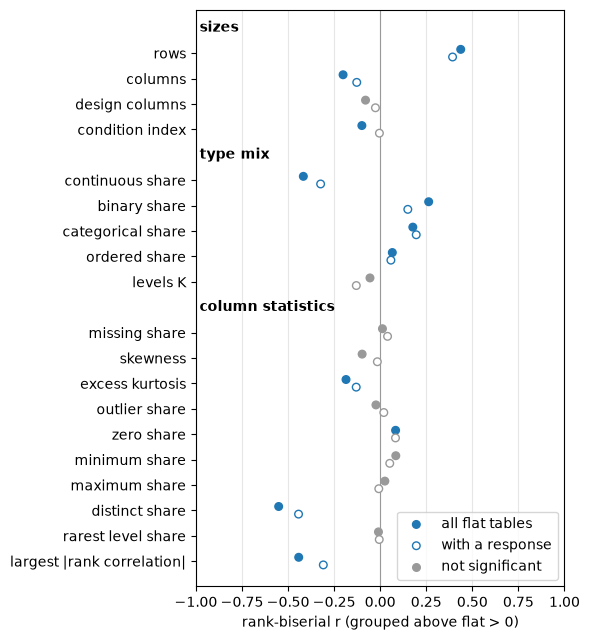

In [2]:
ALPHA = 0.05  # a Holm-adjusted p at or above it is grey
BLOCKS = {'sizes': 4, 'type mix': 5, 'column statistics': 10}  # consecutive statistics of tests.csv
SIDES = {  # label, vertical offset, filled marker
    'all': ('all flat tables', -0.15, True),
    'response': ('with a response', 0.15, False),
}

statistics = tests['statistic'].unique()
r = tests.pivot(index='statistic', columns='flat', values='rank_biserial').loc[statistics]
p = tests.pivot(index='statistic', columns='flat', values='p_holm').loc[statistics]
y = []  # a row per statistic, a heading row above each block
headings = {}
row = 0
for name, count in BLOCKS.items():
    headings[name] = row
    y.extend(range(row + 1, row + 1 + count))
    row += count + 1
y = np.array(y)

fig, ax = plt.subplots(figsize=(6, 6.5))
ax.axvline(0, color='0.6', linewidth=0.8)
for side, (label, offset, filled) in SIDES.items():
    color = np.where(p[side] < ALPHA, 'C0', '0.6')
    face = color if filled else 'white'
    ax.scatter(r[side], y + offset, s=30, edgecolors=color, facecolors=face, label=label, zorder=3)
ax.scatter([], [], s=30, color='0.6', label='not significant')
for name, row in headings.items():
    ax.text(-0.98, row, name, va='center', fontweight='bold')
ax.set(
    xlim=(-1, 1),
    ylim=(y[-1] + 1, -0.7),
    yticks=y,
    yticklabels=[NAMES[s] for s in statistics],
    xlabel='rank-biserial r (grouped above flat > 0)',
)
ax.grid(axis='x', color='0.9')
ax.set_axisbelow(True)
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig('effects.pdf')

## Finding

**Grouped and flat tables differ most in size, type mix and how distinct their values are:**
1. Grouped tables have more rows and more binary and categorical columns. Flat tables more continuous ones.
2. Flat tables' columns hold more distinct values and correlate more strongly.
3. Skewness, outliers, extremes and missing values barely differ.
4. The size of the effect slightly shrinks when discarding tables without a documented response. 